In [6]:

import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

from optimization.generators import generate_problem_data
from optimization.losses import make_quadratic_loss
from optimization.runner import run_optimization
from optimization.optimizers.collinear import CollinearGradients


# конфигурация

N_VALUES = [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000]
KAPPA_VALUES = [10, 30]
NUM_U0 = 1 # одно начальное приближение

NUM_ITERS = 3000
TOL_DIST = 0.05

LR_ADAM = 0.001
LR_NESTEROV = 0.01
BETAS_ADAM = (0.9, 0.999)
MOMENTUM_NESTEROV = 0.9

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

MAX_ITERS_MAP = {
    "Adam": NUM_ITERS,
    "Метод Нестерова": NUM_ITERS,
    "Метод коллинеарных градиентов": 50,
}

OPTIMIZER_NAMES = [
    "Adam",
    "Метод Нестерова",
    "Метод коллинеарных градиентов",
]


# сиды

def seeds_for(n: int, kappa: int) -> tuple[int, int, int]:
    """Формирует seed для A, b и одного начального приближения."""
    base = 1000 * n + 100 * kappa
    return base, base + 1, base + 2

# оптимизаторы

def make_optimizers(loss_fn):
    return {
        "Adam": (torch.optim.Adam, dict(lr=LR_ADAM, betas=BETAS_ADAM)),
        # Nesterov = SGD с momentum и nesterov=True
        "Метод Нестерова": (torch.optim.SGD, dict(lr=LR_NESTEROV,
                                                 momentum=MOMENTUM_NESTEROV,
                                                 nesterov=True)),
        "Метод коллинеарных градиентов": (CollinearGradients, dict(
            lr=1.0,
            objective_fn=loss_fn,
            c1=1e-8,
            c2=4.0,
            delta0=1e-5,
            h0=1e-8,
        )),
    }


# эксперимент

def run_experiment():
    results = {
        kappa: {
            0: {n: {} for n in N_VALUES}
        }
        for kappa in KAPPA_VALUES
    }

    for kappa in KAPPA_VALUES:
        print(f"\n==================== κ = {kappa} ====================")

        for n in N_VALUES:
            seed_A, seed_b, seed_u0 = seeds_for(n, kappa)

            # генерируем A, b один раз
            data = generate_problem_data(
                n=n, kappa=float(kappa),
                seed_A=seed_A, seed_b=seed_b, seed_u0=seed_u0,
                R=5.0,
            )

            loss_fn = make_quadratic_loss(data["A"], data["b"])
            optimizers = make_optimizers(loss_fn)

            for name, (opt_class, opt_kwargs) in optimizers.items():
                u_final, hist = run_optimization(
                    opt_class,
                    u0_np=data["u0"],
                    loss_fn=loss_fn,
                    u_star_np=data["u_star"],
                    num_iters=MAX_ITERS_MAP[name],
                    tol_dist=TOL_DIST,
                    **opt_kwargs,
                )

                results[kappa][0][n][name] = {
                    "time": hist["time"],
                    "total_evals": hist["f_evals"] + hist["grad_evals"],
                }

            # короткий лог
            parts = []
            for name in optimizers:
                r = results[kappa][0][n][name]
                parts.append(f"u0#1/{name[:3]}: {r['time']:.3f}s")

            print(f"  n={n:<5} " + "  ".join(parts))

    return results


# запуск

t0 = time.perf_counter()
results = run_experiment()
print(f"\nВсе эксперименты заняли {time.perf_counter() - t0:.1f} с")


==================== κ = 10 ====================
  n=1000  u0#1/Ada: 0.452s  u0#1/Мет: 0.017s  u0#1/Мет: 0.006s
  n=2000  u0#1/Ada: 0.889s  u0#1/Мет: 0.054s  u0#1/Мет: 0.021s
  n=3000  u0#1/Ada: 2.379s  u0#1/Мет: 0.176s  u0#1/Мет: 0.058s
  n=4000  u0#1/Ada: 3.296s  u0#1/Мет: 0.306s  u0#1/Мет: 0.115s
  n=5000  u0#1/Ada: 4.582s  u0#1/Мет: 0.459s  u0#1/Мет: 0.178s
  n=6000  u0#1/Ada: 6.219s  u0#1/Мет: 0.694s  u0#1/Мет: 0.262s
  n=7000  u0#1/Ada: 8.351s  u0#1/Мет: 1.009s  u0#1/Мет: 0.397s
  n=8000  u0#1/Ada: 9.760s  u0#1/Мет: 1.272s  u0#1/Мет: 0.482s
  n=9000  u0#1/Ada: 12.633s  u0#1/Мет: 1.650s  u0#1/Мет: 0.621s
  n=10000 u0#1/Ada: 14.094s  u0#1/Мет: 2.035s  u0#1/Мет: 0.809s

==================== κ = 30 ====================
  n=1000  u0#1/Ada: 0.680s  u0#1/Мет: 0.014s  u0#1/Мет: 0.009s
  n=2000  u0#1/Ada: 1.223s  u0#1/Мет: 0.045s  u0#1/Мет: 0.027s
  n=3000  u0#1/Ada: 2.941s  u0#1/Мет: 0.119s  u0#1/Мет: 0.071s
  n=4000  u0#1/Ada: 4.283s  u0#1/Мет: 0.241s  u0#1/Мет: 0.142s
  n=5000  u0#1/A

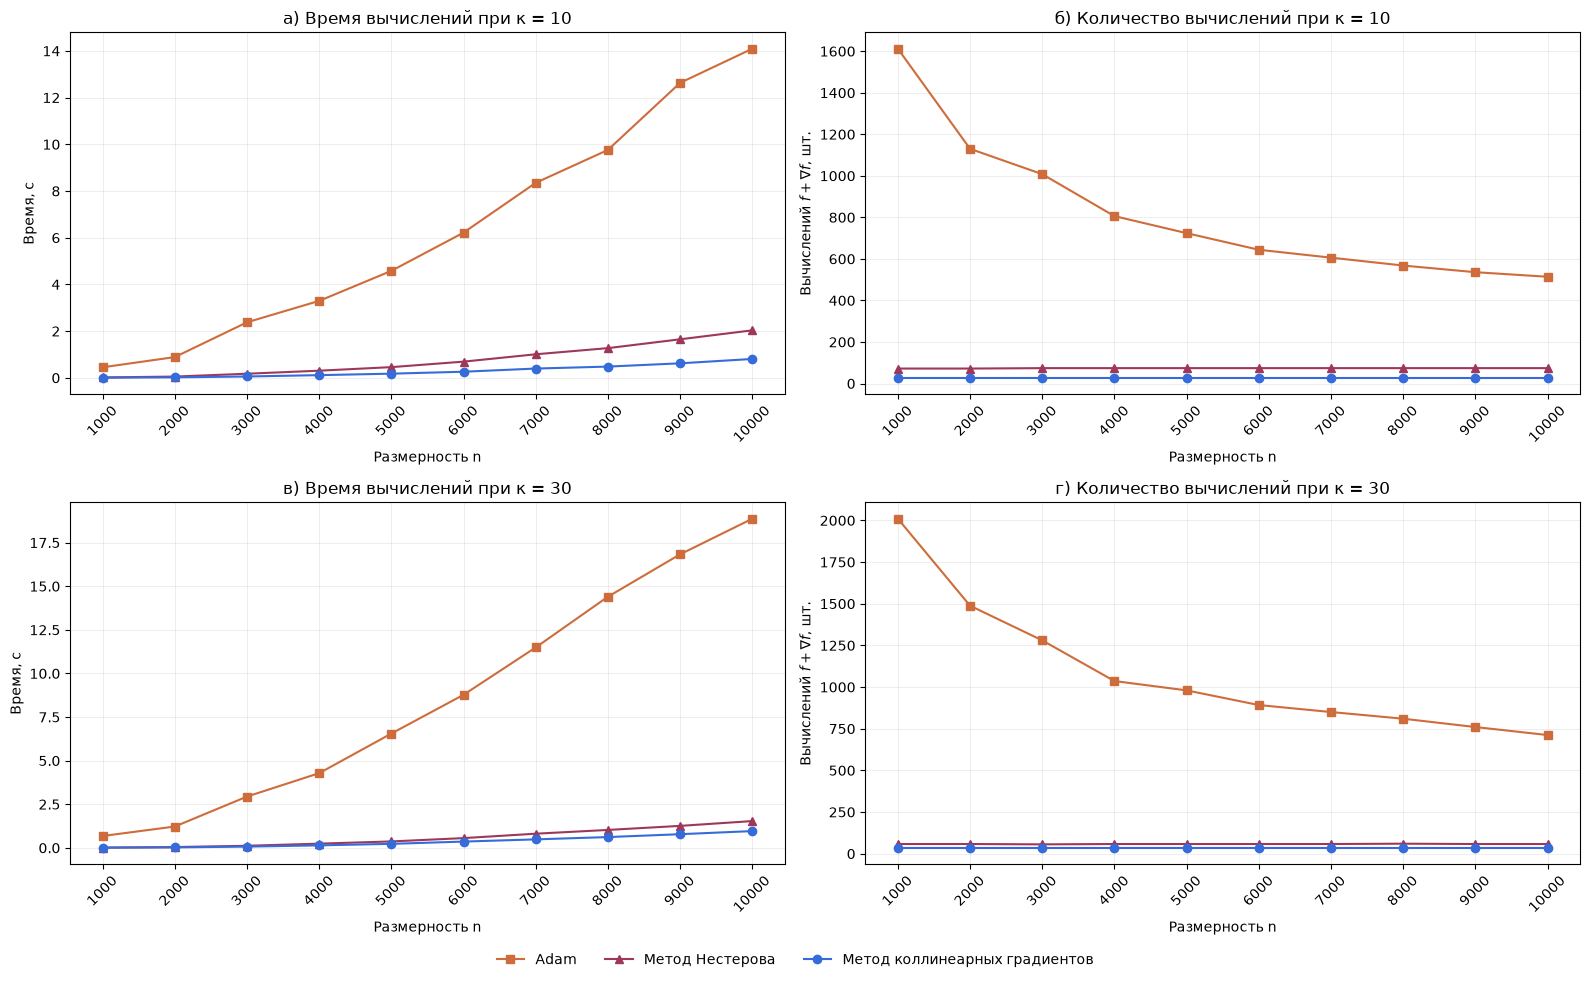

Сохранено: C:\Users\Mikhail\repos\Optimization\experiments\results\comparison_kappa10_30.png


In [10]:

# графики

COLORS = {
    "Adam": "C1",
    "Метод Нестерова": "C2",
    "Метод коллинеарных градиентов": "C0",
}
MARKERS = {
    "Adam": "s",
    "Метод Нестерова": "^",
    "Метод коллинеарных градиентов": "o",
}

# Обозначения графиков
PLOT_LABELS = ["а)", "б)", "в)", "г)"]

# Обусловленности для построения графиков
PLOT_KAPPA_VALUES = [10, 30]

# Размерности для построения графиков
PLOT_N_VALUES = [
    1000, 2000, 3000, 4000, 5000,
    6000, 7000, 8000, 9000, 10000
]

# Построение графиков
fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10),
    facecolor="white"
)

# Общая легенда
legend_handles = []

for name in OPTIMIZER_NAMES:
    line, = axes[0, 0].plot(
        [],
        [],
        marker=MARKERS[name],
        color=COLORS[name],
        label=name
    )
    legend_handles.append(line)

for row_idx, kappa in enumerate(PLOT_KAPPA_VALUES):
    ax_time = axes[row_idx, 0]
    ax_evals = axes[row_idx, 1]

    for name in OPTIMIZER_NAMES:
        times = [
            results[kappa][0][n][name]["time"]
            for n in PLOT_N_VALUES
        ]

        evals = [
            results[kappa][0][n][name]["total_evals"]
            for n in PLOT_N_VALUES
        ]

        ax_time.plot(
            PLOT_N_VALUES, times,
            marker=MARKERS[name],
            color=COLORS[name]
        )

        ax_evals.plot(
            PLOT_N_VALUES, evals,
            marker=MARKERS[name],
            color=COLORS[name]
        )

    for ax in (ax_time, ax_evals):
        ax.set_facecolor("white")
        ax.tick_params(colors="black")
        ax.xaxis.label.set_color("black")
        ax.yaxis.label.set_color("black")
        ax.title.set_color("black")
        ax.ticklabel_format(
            style="plain",
            axis="both",
            useOffset=False
        )

        for spine in ax.spines.values():
            spine.set_color("black")

    # Левый столбец: время
    plot_idx = row_idx * 2

    ax_time.set_xlabel("Размерность n")
    ax_time.set_ylabel("Время, с")
    ax_time.set_title(
        f"{PLOT_LABELS[plot_idx]} Время вычислений при κ = {kappa}"
    )
    ax_time.set_xticks(PLOT_N_VALUES)
    ax_time.tick_params(axis="x", rotation=45)
    ax_time.grid(True, alpha=0.3)

    # Правый столбец: количество вычислений
    ax_evals.set_xlabel("Размерность n")
    ax_evals.set_ylabel(r"Вычислений $f + \nabla f$, шт.")
    ax_evals.set_title(
        f"{PLOT_LABELS[plot_idx + 1]} Количество вычислений при κ = {kappa}"
    )
    ax_evals.set_xticks(PLOT_N_VALUES)
    ax_evals.tick_params(axis="x", rotation=45)
    ax_evals.grid(True, alpha=0.3)


# Одна общая легенда внизу
fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.015),
    ncol=3,
    fontsize=10,
    frameon=False,
    labelcolor="black"
)

# Настройка расположения
fig.tight_layout(rect=(0, 0.045, 1, 1))

out_path = RESULTS_DIR / "comparison_kappa10_30.png"

fig.savefig(
    out_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="white"
)

plt.show()
print(f"Сохранено: {out_path.resolve()}")

